# Chapter 8: Wideband Robust Beamforming for Sub-Terahertz 6G Links

Companion code for *Robust Adaptive Beamforming and Its Applications* by Ayman Elnashar (Wiley, forthcoming).

This notebook reproduces every simulation figure of Chapter 8 (Figures 8.1–8.11), Tables 8.2 and 8.3 and the numbers quoted in the text. The chapter develops WRAB, a wideband robust adaptive beamformer for fully digital sub-terahertz arrays. For every processed subcarrier it keeps a fan of worst-case constraints whose steering vectors are evaluated at that subcarrier's frequency, so the deterministic carrier-referenced steering error (beam squint) is removed from the constraint set, while the fan and its per-constraint margins absorb steering mismatch and pointing error. Each snapshot takes a scale-invariant gradient step on the output power and then the exact Euclidean projection onto the intersection of the worst-case constraints (Algorithm 8.1); the margins are anchored once to the covariance and then follow the alignment of its dominant eigenvector, (8.18)–(8.20).

## Configuration

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..'))   # chapter folder, so that `ch8wrab` imports without installation
QUICK = False             # True: two or three trials per point (smoke test)
REUSE_DATA = True         # True: reuse the simulation data in FIGDIR/data when it is complete (e.g. written by scripts/generate_figures.py)
FIGDIR = os.path.abspath('../figures')
os.environ.update(FIGDIR=FIGDIR, RAB_INLINE='1')
%matplotlib inline
from ch8wrab import scenarios as S
from ch8wrab.figures import *
DATA = os.path.join(FIGDIR, 'data')

def show(key):
    print(json.dumps(RESULTS[key], ensure_ascii=False, indent=1)[:3000])

## Library

`ch8wrab.algorithms` holds the ULA model at 300 GHz (subcarrier frequencies (8.1), frequency-dependent steering vectors, carrier-fixed analog response, 3-dB beamwidth), the `Scenario` settings of Table 8.1, the trial generator (block-static desired-direction jitter, optional three-path angular spread, interference-only or signal-present training), WRAB (`train_subband`: covariance (8.10), gradient step (8.11)–(8.13), exact projection (8.14) by an active-set Newton solve of its dual with Dykstra's method as a checked fallback, margins (8.18)–(8.20)), the comparators of Section 8.4, the output SINR (8.5) and the trial bootstrap. `ch8wrab.scenarios` defines one stage per group of results, `ch8wrab.figures` one function per figure and `ch8wrab.verify` the comparison with the chapter.

A short example: one 64-element trial at a two-degree mismatch.

In [2]:
import numpy as np
from ch8wrab import algorithms as C
cfg = C.Scenario(M=64, Nsc=3, K=300, mismatch_deg=2, jitter_deg=0.1)
r = C.evaluate_trial(cfg, C.seed_for('example', 0), C.CORE_METHODS)
print({C.METHOD_LABELS[m]: round(float(np.mean(10*np.log10(v))), 2) for m, v in r['linear'].items()})
print('largest constraint residual:', max(r['max_residual'].values()))

{'Analog-only': 2.96, 'WC-single (carrier-referenced)': 2.95, 'WRAB': 18.91}
largest constraint residual: 9.19130105359045e-10


## Settings (Section 8.4, Table 8.1)

300 GHz carrier, 20 GHz band (40 GHz in the grid ablation), ULA with half-wavelength spacing at the carrier; 64 elements in the core sweeps, 128 in Figures 8.8–8.10, 64–512 in the scaling test. SNR 5 dB and INR 10 dB per element, interferers at 45° and −60° unless stated. Forgetting factor 0.97, step relaxation 0.1, relative covariance load 10⁻⁶. Constraint fan at (0, −0.6, +0.6, −1.2) beamwidths around the presumed direction (fixed offsets in degrees in Figures 8.3, 8.8–8.10; symmetric (0, ±0.6, ±1.2) beamwidths in Figure 8.11). Initial margins (1.9, 1.5, 1.5, 1.1), reset to the covariance anchor at the first margin update (snapshot 60: warm-up of 50, period 30), retained eigenspace order ⌈0.25M⌉, ceiling 3. Single-ball radius 0.6√M (0.85√M in Figure 8.11, 3.8 in Figure 8.3). Training snapshots contain interference and noise only, except in the signal-present control. Each quasi-static run is scored with its final weight vector; a plotted point is the trial mean of the per-subcarrier SINR in dB with a 95% bootstrap interval over trials (2000 resamples). Seed 42 with an independent stream per experiment.

## Experiments

Each stage runs in its own process and writes its data and printed output into `FIGDIR/data`. The full counts take about 12 minutes on two cores; the timing stage runs alone at the end.

In [3]:
def complete():
    return all(os.path.exists(os.path.join(DATA, s + '.json')) for s in S.ALL_STAGES)

if REUSE_DATA and complete() and not QUICK:
    print('reusing the simulation data in', DATA)
else:
    S.run_groups(DATA, groups=S.ALL_STAGES, jobs=2, quick=QUICK)
for s in S.ALL_STAGES:
    print(f"{s:12s} {json.load(open(os.path.join(DATA, s + '.json')))['seconds']:8.1f} s")

reusing the simulation data in /home/claude/robust-adaptive-beamforming-book/chapter-08/figures/data
fig11           252.3 s
fig11ref         93.8 s
near            169.5 s
fixedangle      184.0 s
controls         45.9 s
fig5            103.8 s
dynamic          83.0 s
fig8             73.0 s
fig4             58.3 s
fig6             59.2 s
fig7             96.0 s
table3           50.3 s
fig9             31.4 s
fig3             19.6 s
fig10            25.1 s
feasibility      13.5 s
analytic          0.1 s
timing           31.8 s


## Figure 8.1: Beam-squint array-factor loss

Carrier-fixed phase weights steered to 30°, N = 16, 64 and 256, frequency offsets across the 20 GHz band at 300 GHz.

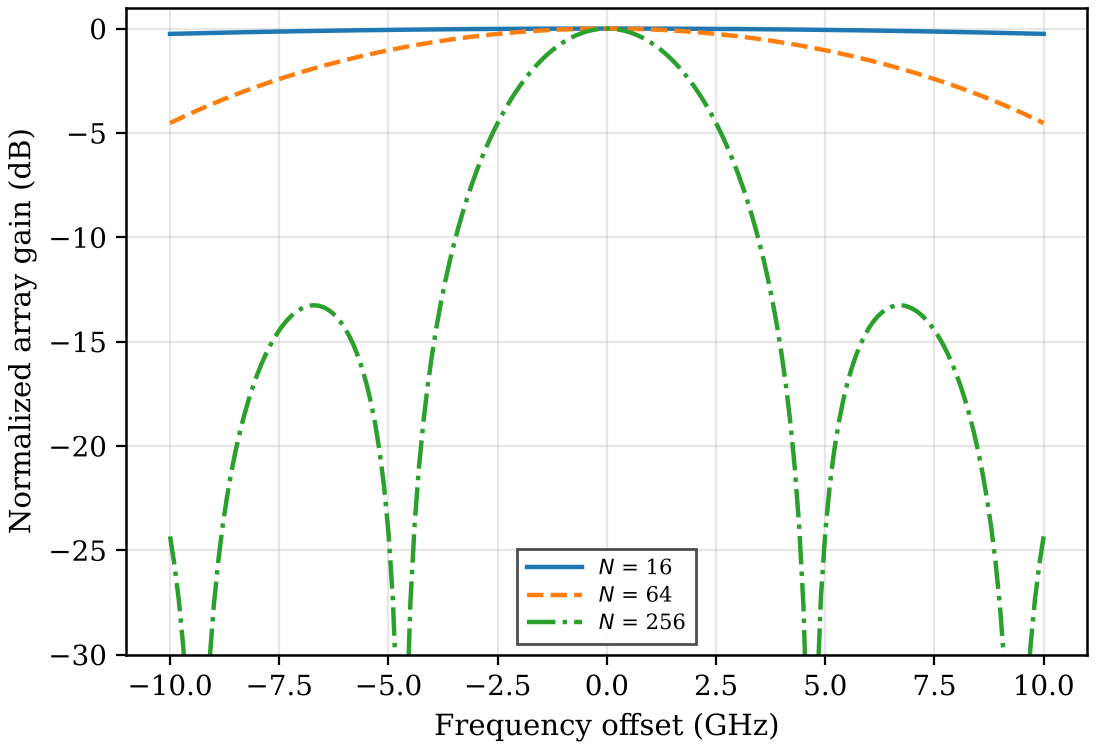

{
 "N=16": {
  "band_edge_loss_db": -0.255,
  "deepest_db": -0.255
 },
 "N=64": {
  "band_edge_loss_db": -4.53,
  "deepest_db": -4.53
 },
 "N=256": {
  "band_edge_loss_db": -24.337,
  "deepest_db": -51.504
 },
 "offsets_GHz": [
  -10.0,
  10.0
 ]
}


In [4]:
fig_8_1()
show('Figure 8.1')

## Figure 8.2: Expected power-gain loss under pointing error

Gaussian pointing error at broadside, expectation of the power gain by 256-node Gauss–Hermite quadrature, N = 64 and 256.

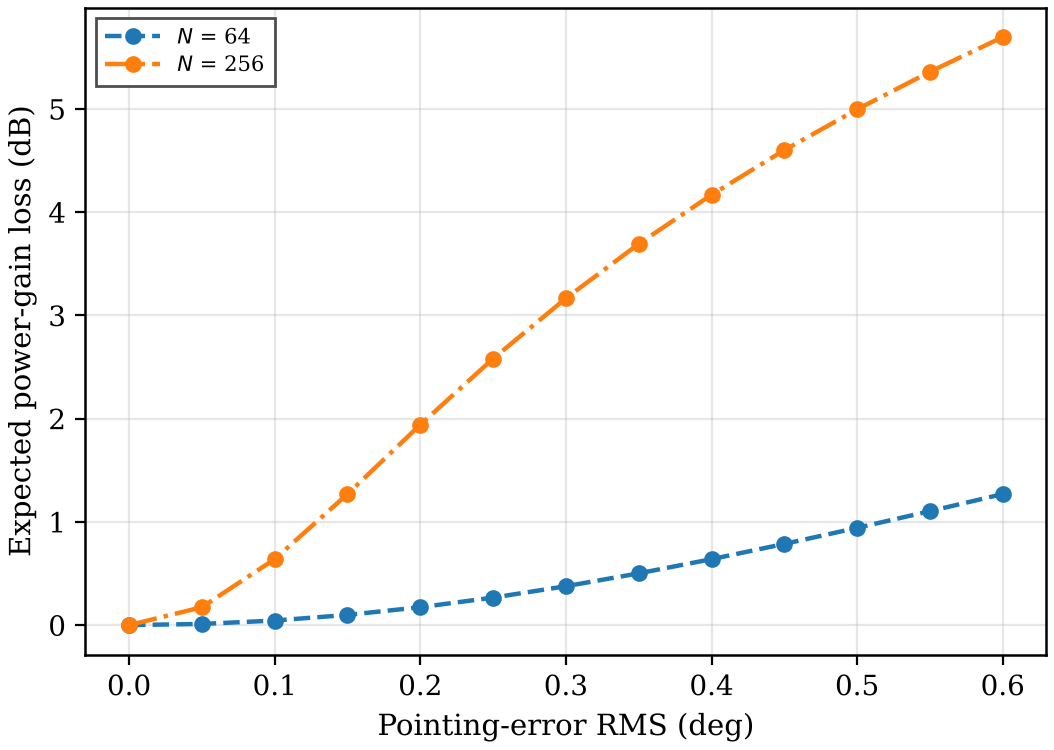

{
 "N=64": {
  "0": -0.0,
  "0.05": 0.011,
  "0.1": 0.044,
  "0.15": 0.099,
  "0.2": 0.173,
  "0.25": 0.266,
  "0.3": 0.376,
  "0.35": 0.501,
  "0.4": 0.639,
  "0.45": 0.786,
  "0.5": 0.942,
  "0.55": 1.103,
  "0.6": 1.269
 },
 "N=256": {
  "0": -0.0,
  "0.05": 0.173,
  "0.1": 0.639,
  "0.15": 1.269,
  "0.2": 1.941,
  "0.25": 2.581,
  "0.3": 3.165,
  "0.35": 3.692,
  "0.4": 4.168,
  "0.45": 4.6,
  "0.5": 4.996,
  "0.55": 5.359,
  "0.6": 5.695
 }
}


In [5]:
fig_8_2()
show('Figure 8.2')

## Figure 8.3: Per-subcarrier SINR across the band

N = 64, 11 subcarriers, 2° mismatch, 0.1° RMS jitter, fixed offsets (0, ±1.5, −3)°, single-ball radius 3.8; 15 trials.

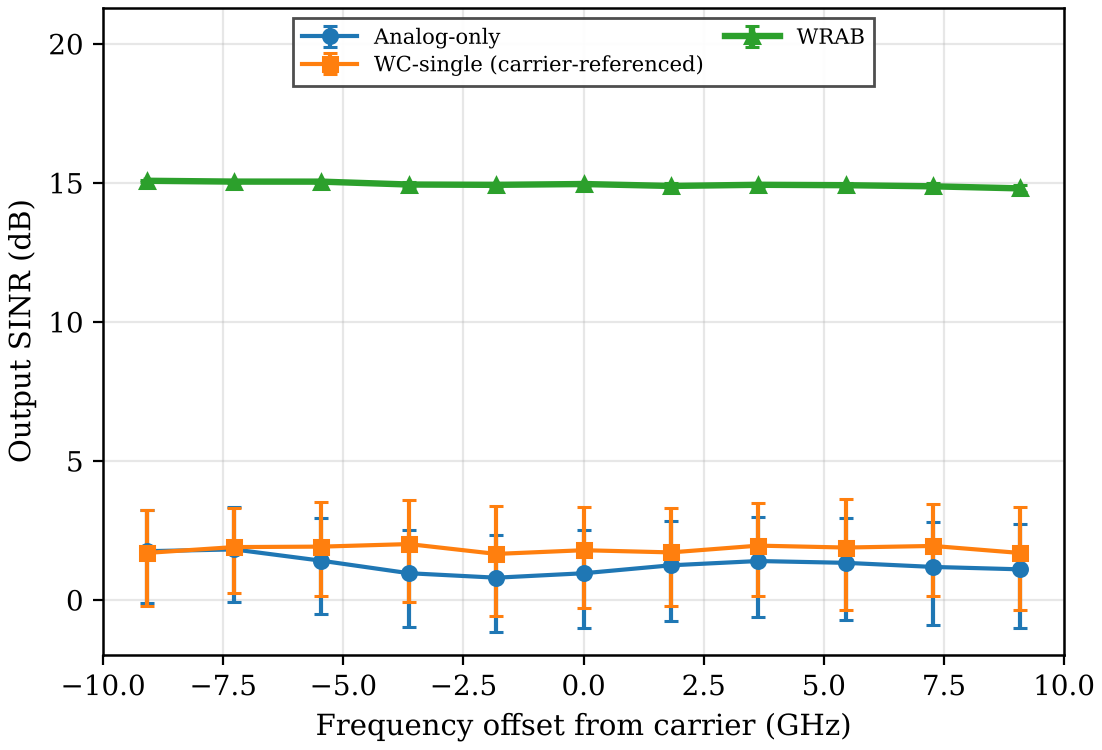

{
 "Analog-only": {
  "per_subcarrier_db": [
   1.75,
   1.814,
   1.407,
   0.959,
   0.798,
   0.957,
   1.243,
   1.397,
   1.332,
   1.185,
   1.098
  ],
  "band_mean_db": 1.267
 },
 "WC-single (carrier-referenced)": {
  "per_subcarrier_db": [
   1.688,
   1.898,
   1.915,
   2.006,
   1.653,
   1.786,
   1.707,
   1.95,
   1.882,
   1.939,
   1.686
  ],
  "band_mean_db": 1.828
 },
 "WRAB": {
  "per_subcarrier_db": [
   15.072,
   15.043,
   15.042,
   14.937,
   14.926,
   14.955,
   14.886,
   14.928,
   14.914,
   14.873,
   14.798
  ],
  "band_mean_db": 14.943
 }
}


In [6]:
fig_8_3()
show('Figure 8.3')

## Figure 8.4: SINR against steering mismatch

N = 64, 8 subcarriers, mismatch 0–6°, 0.15° RMS jitter, asymmetric grid of Table 8.1; 15 trials.

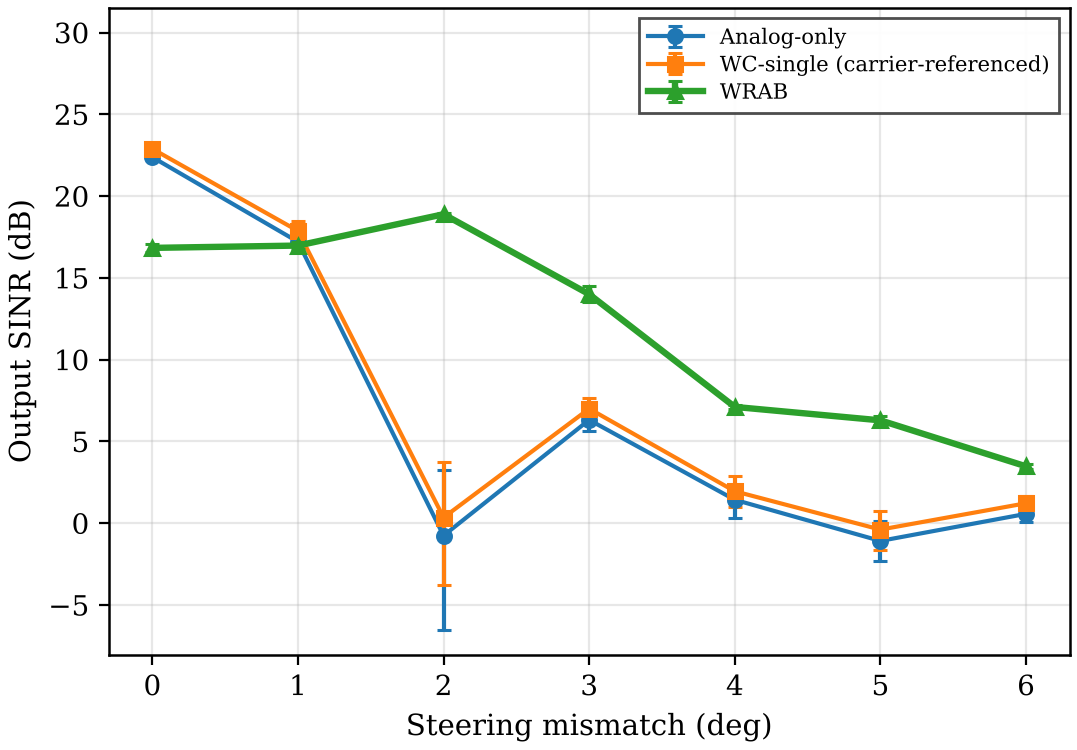

{
 "x": [
  0,
  1,
  2,
  3,
  4,
  5,
  6
 ],
 "points": {
  "Analog-only": {
   "0": {
    "mean_db": 22.377,
    "ci95": [
     22.347,
     22.403
    ]
   },
   "1": {
    "mean_db": 17.201,
    "ci95": [
     16.563,
     17.844
    ]
   },
   "2": {
    "mean_db": -0.764,
    "ci95": [
     -6.56,
     3.233
    ]
   },
   "3": {
    "mean_db": 6.312,
    "ci95": [
     5.627,
     6.985
    ]
   },
   "4": {
    "mean_db": 1.427,
    "ci95": [
     0.326,
     2.348
    ]
   },
   "5": {
    "mean_db": -1.089,
    "ci95": [
     -2.332,
     0.111
    ]
   },
   "6": {
    "mean_db": 0.565,
    "ci95": [
     0.078,
     0.969
    ]
   }
  },
  "WC-single (carrier-referenced)": {
   "0": {
    "mean_db": 22.887,
    "ci95": [
     22.857,
     22.911
    ]
   },
   "1": {
    "mean_db": 17.867,
    "ci95": [
     17.225,
     18.475
    ]
   },
   "2": {
    "mean_db": 0.341,
    "ci95": [
     -3.776,
     3.755
    ]
   },
   "3": {
    "mean_db": 6.997,
    "ci95": [
     6

In [7]:
fig_8_4()
show('Figure 8.4')

## Figure 8.5: Off-broadside steering

N = 64, 11 subcarriers, nominal direction 0–60°, 2° mismatch, interferers 25° above and 35° below the source; 15 trials.

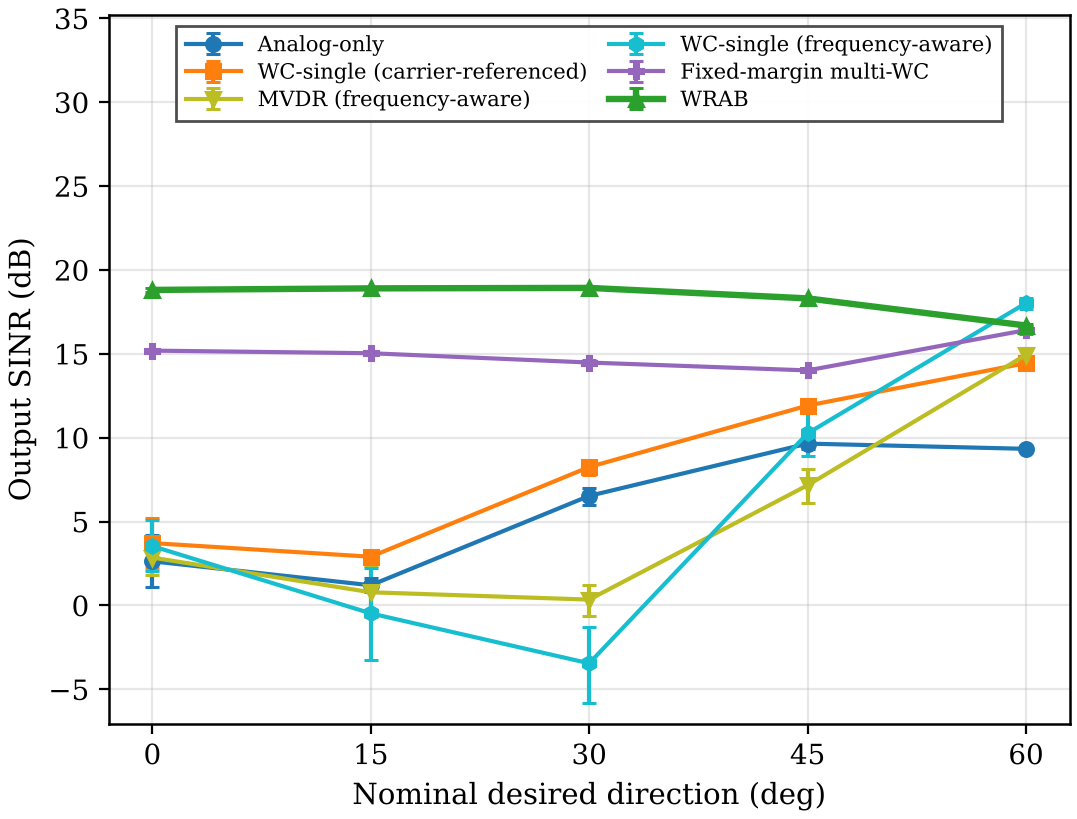

{
 "x": [
  0,
  15,
  30,
  45,
  60
 ],
 "points": {
  "Analog-only": {
   "0": {
    "mean_db": 2.63,
    "ci95": [
     1.078,
     4.19
    ]
   },
   "15": {
    "mean_db": 1.202,
    "ci95": [
     0.779,
     1.646
    ]
   },
   "30": {
    "mean_db": 6.531,
    "ci95": [
     5.979,
     6.977
    ]
   },
   "45": {
    "mean_db": 9.649,
    "ci95": [
     9.298,
     9.946
    ]
   },
   "60": {
    "mean_db": 9.337,
    "ci95": [
     9.232,
     9.419
    ]
   }
  },
  "WC-single (carrier-referenced)": {
   "0": {
    "mean_db": 3.717,
    "ci95": [
     2.26,
     5.205
    ]
   },
   "15": {
    "mean_db": 2.904,
    "ci95": [
     2.603,
     3.252
    ]
   },
   "30": {
    "mean_db": 8.253,
    "ci95": [
     7.797,
     8.641
    ]
   },
   "45": {
    "mean_db": 11.917,
    "ci95": [
     11.578,
     12.201
    ]
   },
   "60": {
    "mean_db": 14.447,
    "ci95": [
     14.315,
     14.564
    ]
   }
  },
  "MVDR (frequency-aware)": {
   "0": {
    "mean_db": 2.85

In [8]:
fig_8_5()
show('Figure 8.5')

## Figure 8.6: Interferer proximity

N = 64, 8 subcarriers, one interferer 3–40° from the source and one at −55°, 2° mismatch; 18 trials.

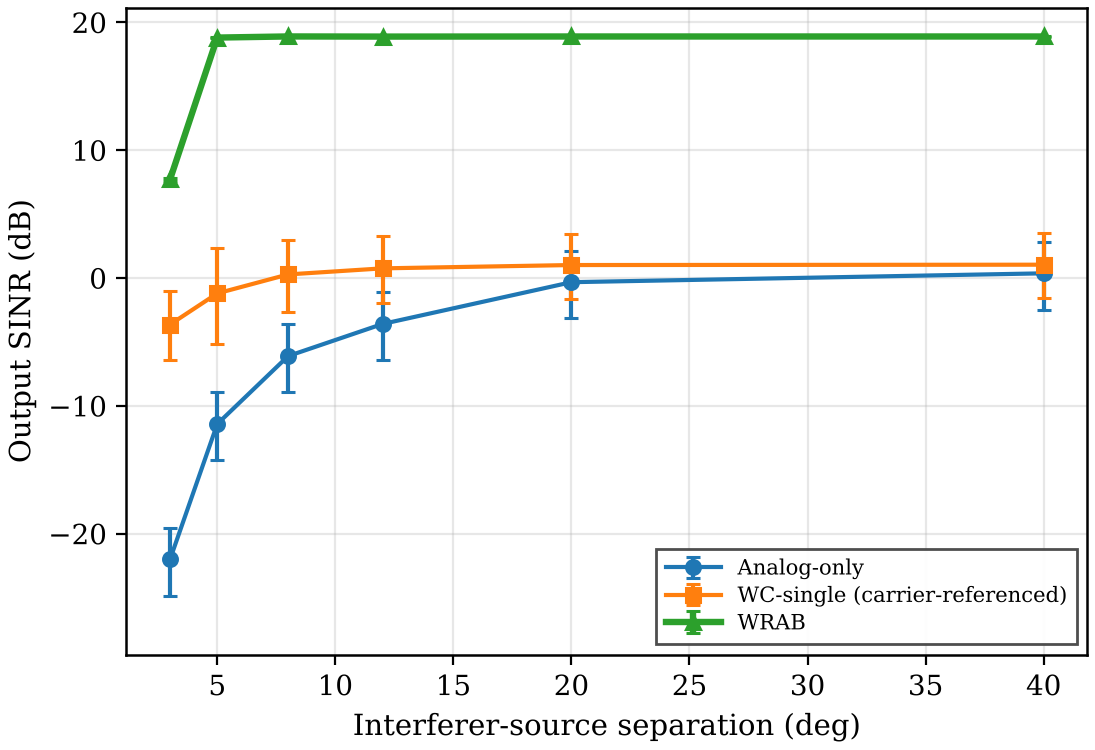

{
 "x": [
  3,
  5,
  8,
  12,
  20,
  40
 ],
 "points": {
  "Analog-only": {
   "3": {
    "mean_db": -22.015,
    "ci95": [
     -24.855,
     -19.538
    ]
   },
   "5": {
    "mean_db": -11.424,
    "ci95": [
     -14.264,
     -8.946
    ]
   },
   "8": {
    "mean_db": -6.11,
    "ci95": [
     -8.95,
     -3.632
    ]
   },
   "12": {
    "mean_db": -3.597,
    "ci95": [
     -6.437,
     -1.12
    ]
   },
   "20": {
    "mean_db": -0.328,
    "ci95": [
     -3.168,
     2.149
    ]
   },
   "40": {
    "mean_db": 0.365,
    "ci95": [
     -2.475,
     2.843
    ]
   }
  },
  "WC-single (carrier-referenced)": {
   "3": {
    "mean_db": -3.641,
    "ci95": [
     -6.447,
     -0.988
    ]
   },
   "5": {
    "mean_db": -1.205,
    "ci95": [
     -5.183,
     2.334
    ]
   },
   "8": {
    "mean_db": 0.279,
    "ci95": [
     -2.658,
     2.995
    ]
   },
   "12": {
    "mean_db": 0.754,
    "ci95": [
     -1.982,
     3.306
    ]
   },
   "20": {
    "mean_db": 1.014,
    "ci95

In [9]:
fig_8_6()
show('Figure 8.6')

## Figure 8.7: Array-size scaling

(a) Mismatch of 1.5 reference beamwidths and 0.3 beamwidths of RMS jitter. (b) Mismatch of 1° for every N with 0.1° of jitter, with the fan of Table 8.1 and with a fan of span ±1.5° and spacing 0.6 beamwidths. 5 subcarriers, 12 trials.

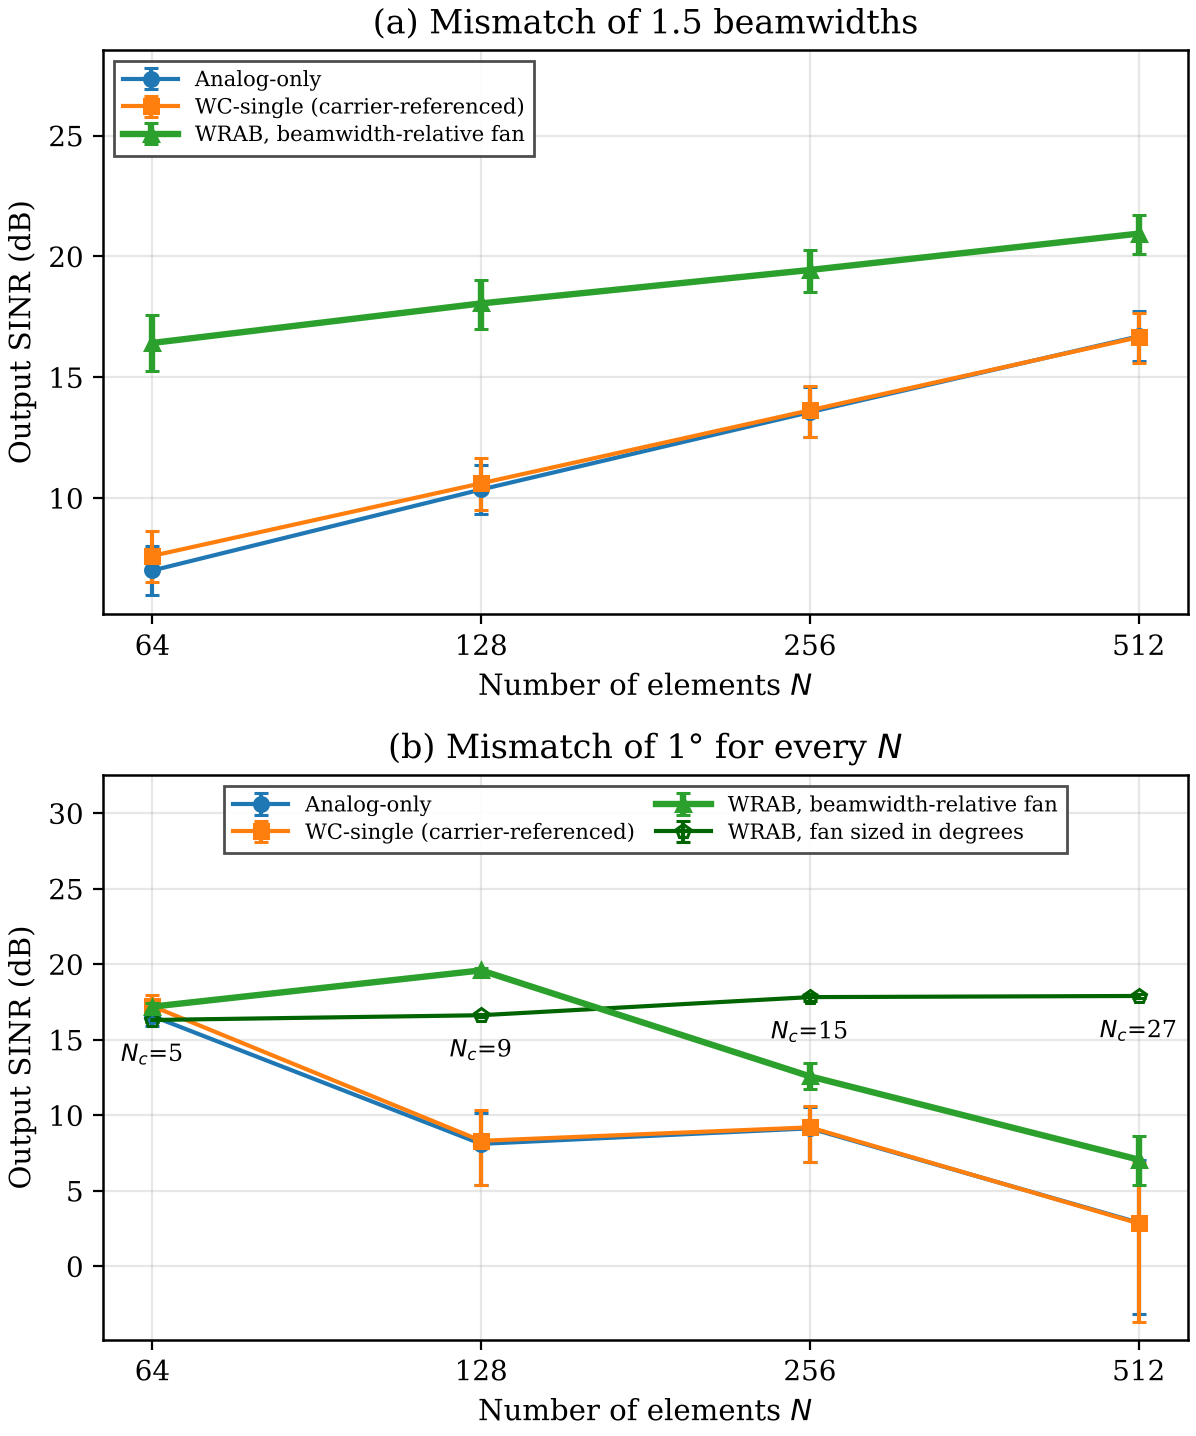

{
 "x": [
  64,
  128,
  256,
  512
 ],
 "points": {
  "Analog-only": {
   "64": {
    "mean_db": 7.001,
    "ci95": [
     5.973,
     8.034
    ]
   },
   "128": {
    "mean_db": 10.353,
    "ci95": [
     9.326,
     11.384
    ]
   },
   "256": {
    "mean_db": 13.554,
    "ci95": [
     12.527,
     14.585
    ]
   },
   "512": {
    "mean_db": 16.691,
    "ci95": [
     15.664,
     17.722
    ]
   }
  },
  "WC-single (carrier-referenced)": {
   "64": {
    "mean_db": 7.607,
    "ci95": [
     6.524,
     8.617
    ]
   },
   "128": {
    "mean_db": 10.609,
    "ci95": [
     9.499,
     11.637
    ]
   },
   "256": {
    "mean_db": 13.633,
    "ci95": [
     12.545,
     14.656
    ]
   },
   "512": {
    "mean_db": 16.655,
    "ci95": [
     15.574,
     17.668
    ]
   }
  },
  "WRAB": {
   "64": {
    "mean_db": 16.418,
    "ci95": [
     15.239,
     17.57
    ]
   },
   "128": {
    "mean_db": 18.054,
    "ci95": [
     17.006,
     19.004
    ]
   },
   "256": {
    "mean_

In [10]:
fig_8_7()
show('Figure 8.7(a)')
show('Figure 8.7(b)')

## Figure 8.8: Misalignment jitter

N = 128, 5 subcarriers, zero commanded mismatch, fixed offsets (0, ±0.4, −0.8)°. (a) Quasi-static desired-direction offset, final weight. (b) AR(1) rotation of the whole array with ρ = 0.99, linear SINR averaged over the last 50 snapshots. 20 trials.

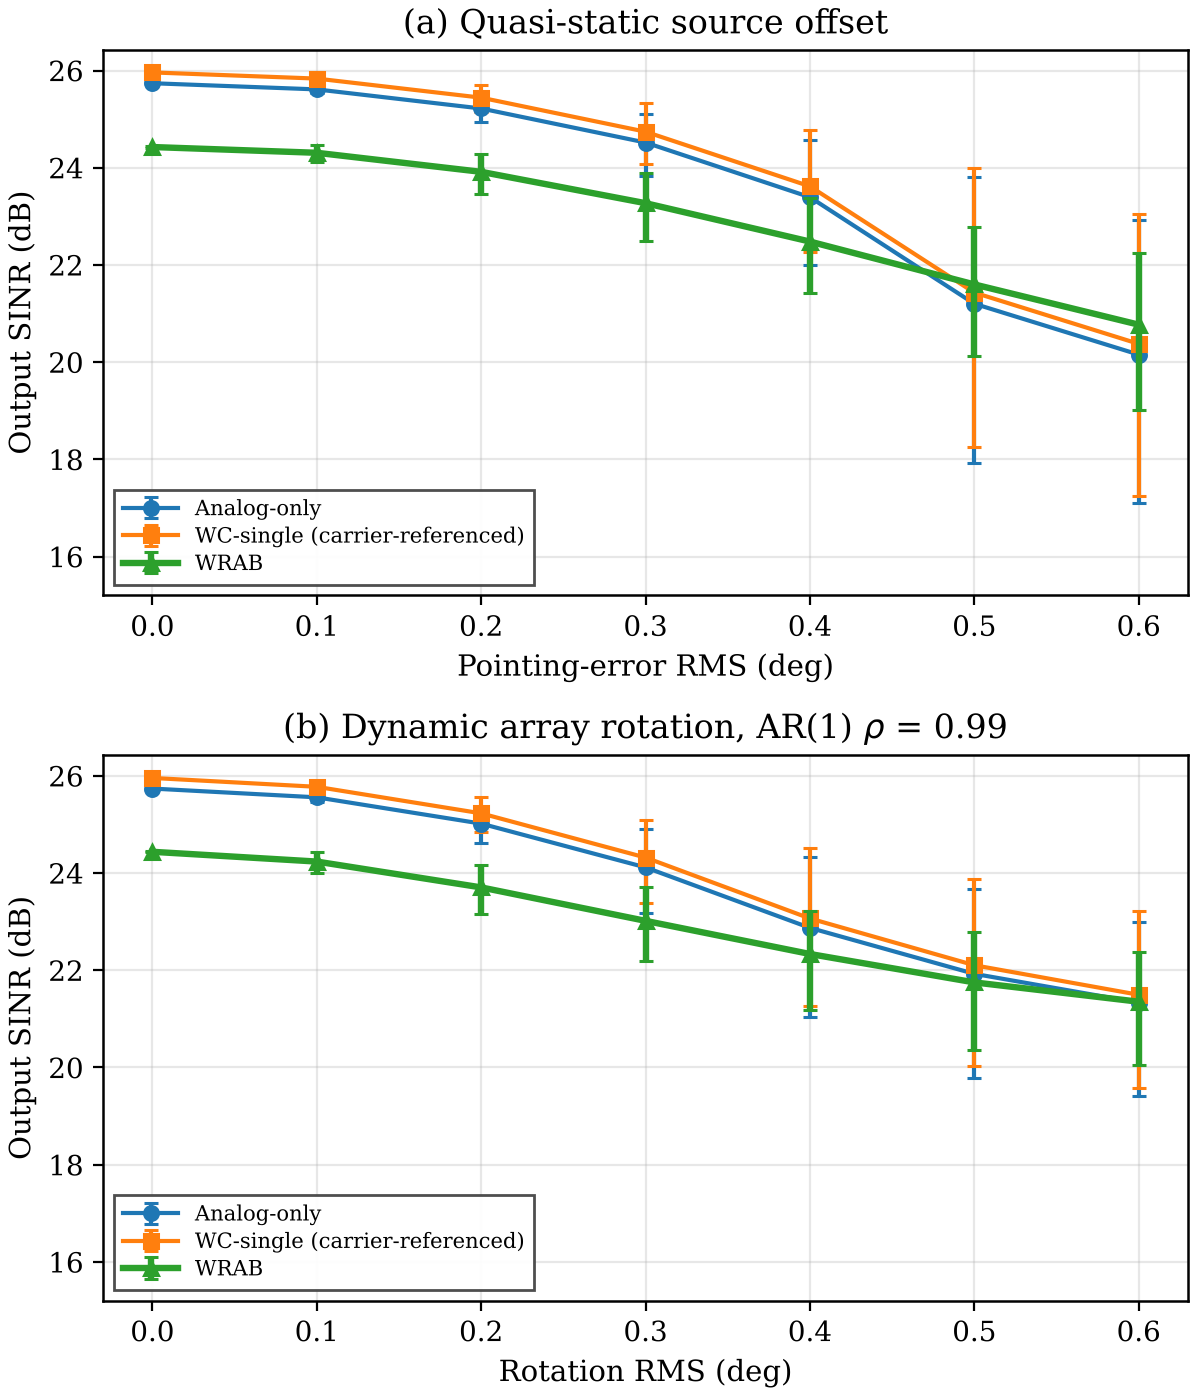

{
 "x": [
  0,
  0.1,
  0.2,
  0.3,
  0.4,
  0.5,
  0.6
 ],
 "points": {
  "Analog-only": {
   "0": {
    "mean_db": 25.739,
    "ci95": [
     25.739,
     25.739
    ]
   },
   "0.1": {
    "mean_db": 25.612,
    "ci95": [
     25.544,
     25.672
    ]
   },
   "0.2": {
    "mean_db": 25.219,
    "ci95": [
     24.938,
     25.469
    ]
   },
   "0.3": {
    "mean_db": 24.518,
    "ci95": [
     23.837,
     25.111
    ]
   },
   "0.4": {
    "mean_db": 23.394,
    "ci95": [
     22.001,
     24.579
    ]
   },
   "0.5": {
    "mean_db": 21.202,
    "ci95": [
     17.919,
     23.805
    ]
   },
   "0.6": {
    "mean_db": 20.155,
    "ci95": [
     17.113,
     22.926
    ]
   }
  },
  "WC-single (carrier-referenced)": {
   "0": {
    "mean_db": 25.961,
    "ci95": [
     25.942,
     25.979
    ]
   },
   "0.1": {
    "mean_db": 25.834,
    "ci95": [
     25.759,
     25.9
    ]
   },
   "0.2": {
    "mean_db": 25.442,
    "ci95": [
     25.155,
     25.693
    ]
   },
   "0.3": {


In [11]:
fig_8_8()
show('Figure 8.8(a)')
show('Figure 8.8(b)')

## Figure 8.9: Grid ablation

N = 128, 40 GHz band, 11 subcarriers: constraint steering vectors at each subcarrier frequency against carrier-referenced ones; 15 trials.

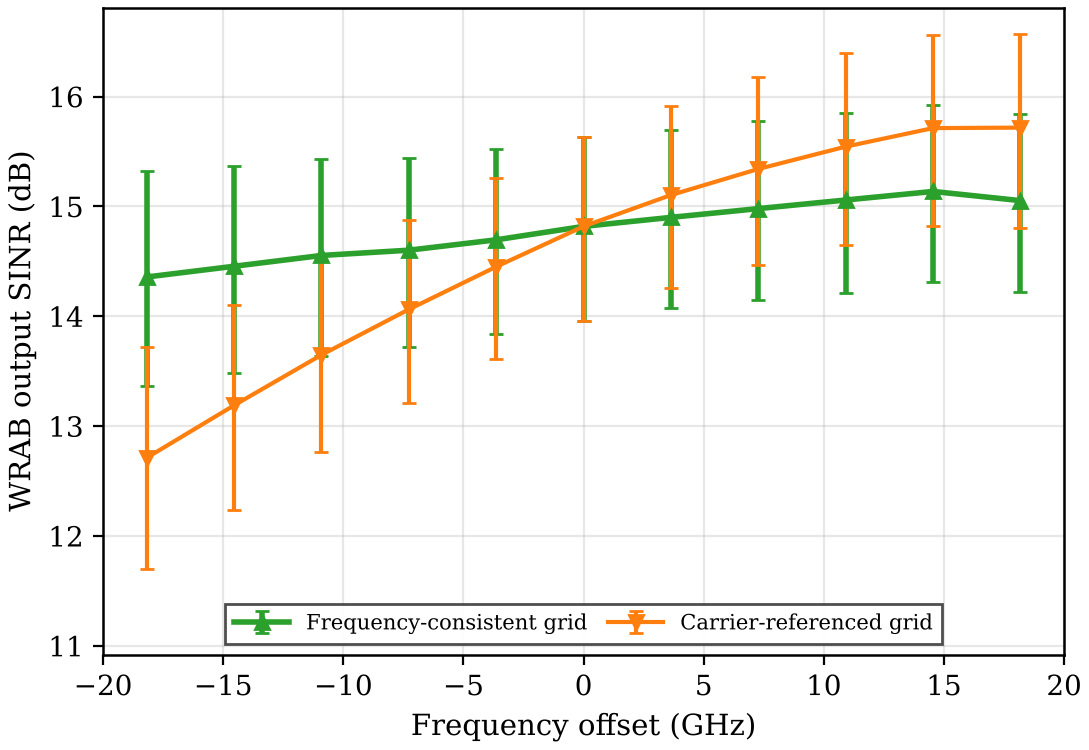

{
 "Frequency-consistent grid": {
  "offsets_GHz": [
   -18.182,
   -14.545,
   -10.909,
   -7.273,
   -3.636,
   0.0,
   3.636,
   7.273,
   10.909,
   14.545,
   18.182
  ],
  "per_subcarrier_db": [
   14.358,
   14.455,
   14.554,
   14.601,
   14.696,
   14.818,
   14.9,
   14.98,
   15.058,
   15.136,
   15.053
  ]
 },
 "Carrier-referenced grid": {
  "offsets_GHz": [
   -18.182,
   -14.545,
   -10.909,
   -7.273,
   -3.636,
   0.0,
   3.636,
   7.273,
   10.909,
   14.545,
   18.182
  ],
  "per_subcarrier_db": [
   12.712,
   13.189,
   13.648,
   14.063,
   14.451,
   14.818,
   15.104,
   15.341,
   15.544,
   15.713,
   15.717
  ]
 }
}


In [12]:
fig_8_9()
show('Figure 8.9')

## Figure 8.10: Margin initialization

N = 128, 3 subcarriers, 220 snapshots, zero mismatch, 0.3° jitter; initial margins 0.1, 1.5 and 3 with adaptation on and with frozen margins; 20 paired trials.

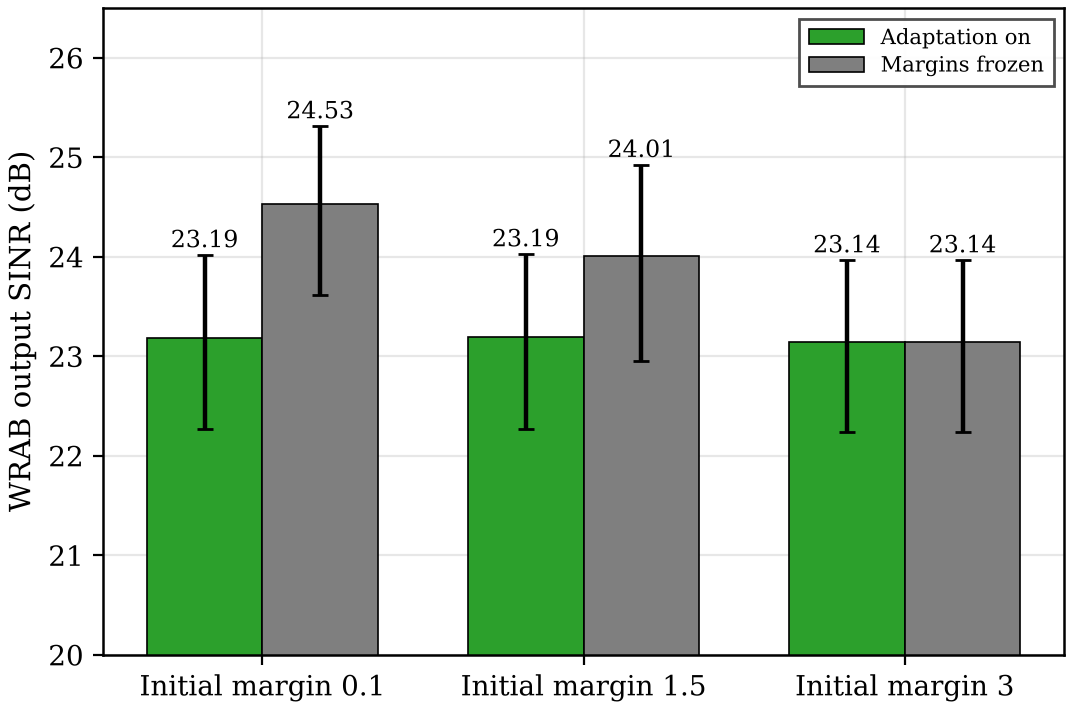

{
 "Adaptation on": {
  "means_db": {
   "0.1": 23.186,
   "1.5": 23.194,
   "3": 23.144
  },
  "spread_db": 0.049
 },
 "Margins frozen": {
  "means_db": {
   "0.1": 24.53,
   "1.5": 24.009,
   "3": 23.144
  },
  "spread_db": 1.386
 }
}


In [13]:
fig_8_10()
show('Figure 8.10')

## Figure 8.11: Ten-method comparison

N = 64, 5 subcarriers, 600 snapshots, interferers at −25° and 40°, symmetric five-point fan with margins starting at 0.3, single-ball radius 0.85√M; exact multi-ball SOCP of (8.8) by CLARABEL with the WRAB balls and final margins; multi-point LCMV with the loading of best mean over 0–2°. 20 trials.

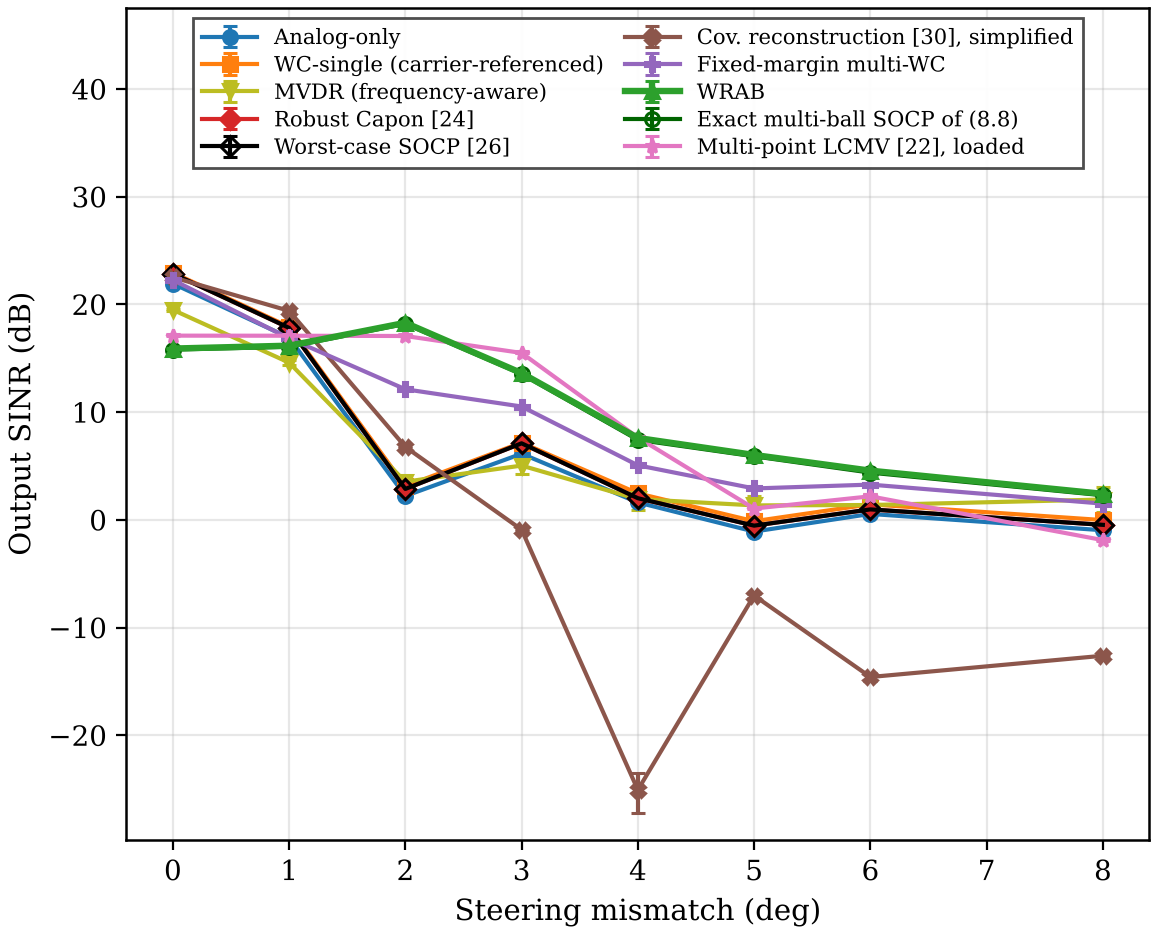

{
 "x": [
  0,
  1,
  2,
  3,
  4,
  5,
  6,
  8
 ],
 "points": {
  "Analog-only": {
   "0": {
    "mean_db": 21.927,
    "ci95": [
     21.927,
     21.927
    ]
   },
   "1": {
    "mean_db": 16.904,
    "ci95": [
     16.904,
     16.904
    ]
   },
   "2": {
    "mean_db": 2.211,
    "ci95": [
     2.211,
     2.211
    ]
   },
   "3": {
    "mean_db": 6.131,
    "ci95": [
     6.131,
     6.131
    ]
   },
   "4": {
    "mean_db": 1.607,
    "ci95": [
     1.607,
     1.607
    ]
   },
   "5": {
    "mean_db": -1.094,
    "ci95": [
     -1.094,
     -1.094
    ]
   },
   "6": {
    "mean_db": 0.544,
    "ci95": [
     0.544,
     0.544
    ]
   },
   "8": {
    "mean_db": -0.973,
    "ci95": [
     -0.973,
     -0.973
    ]
   }
  },
  "WC-single (carrier-referenced)": {
   "0": {
    "mean_db": 22.938,
    "ci95": [
     22.919,
     22.956
    ]
   },
   "1": {
    "mean_db": 17.916,
    "ci95": [
     17.893,
     17.936
    ]
   },
   "2": {
    "mean_db": 3.125,
    "ci95": [

In [14]:
fig_8_11()
show('Figure 8.11')

## Tables 8.1–8.3

Table 8.2: one interferer 2–8° from the source in the Figure 8.6 setting (18 trials), adaptive margins, fixed margins 0.3–3 and the multi-point LCMV with its loading chosen per row. Table 8.3: scenarios S1–S4 at 64 elements, 20 trials, mean ± sample standard deviation.

In [15]:
tables()
for name in ('Table8_2_near_interferer', 'Table8_3_scenarios'):
    print(open(os.path.join(FIGDIR, name + '.md')).read())
print(json.dumps(RESULTS['Table 8.2']['2']['margins'], indent=1))
print(json.dumps(RESULTS['Table 8.2']['3']['margins'], indent=1))

**Table 8.2 - Output SINR (dB) with one interferer near the source, N = 64, 2 deg mismatch. Means of 18 trials; widest 95% interval 0.9 dB.**

| Sep. | Adaptive | Fixed 0.3 | Fixed 1 | Fixed 2 | Fixed 3 | LCMV |
|---|---|---|---|---|---|---|
| 2 deg | 6.2 | -2.9 | -2.9 | -2.9 | -2.9 | -5.2 |
| 3 deg | 7.7 | 0.2 | -1.7 | -2.9 | -3.8 | -5.2 |
| 4 deg | 17.8 | 12.3 | 15.3 | 18.2 | 19.0 | 15.5 |
| 5 deg | 18.8 | 11.4 | 14.3 | 17.3 | 18.8 | 18.5 |
| 8 deg | 18.9 | 11.3 | 14.3 | 17.3 | 18.9 | 18.5 |

**Table 8.3 - Wideband output SINR (dB), mean ± standard deviation, N = 64.**

| Scenario | Analog-only | WC-single | WRAB |
|---|---|---|---|
| S1: 2 deg mismatch, 0.1 deg jitter | 0.1 ± 4.5 | 0.6 ± 4.5 | 18.9 ± 0.1 |
| S2: 4 deg mismatch, 0.2 deg jitter | 1.1 ± 4.8 | 1.7 ± 5.0 | 7.3 ± 0.3 |
| S3: 6 deg mismatch, 0.3 deg jitter | -0.2 ± 1.7 | 0.4 ± 1.6 | 3.5 ± 0.3 |
| S4: 2 deg mismatch, 3-path spread | 1.9 ± 2.7 | 2.4 ± 2.8 | 17.7 ± 3.1 |

{
 "grid_deg": [
  2.0,
  1.047593682643544,
  2.95240

## Numbers quoted in the text

Section 8.3.1: the frozen-norm one-step correction against the exact projection (8.14) on the same 64-element snapshots. Section 8.3.4: the online objective after 600 snapshots against the frozen final problem. Sections 8.5.3, 8.5.8 and 8.5.9: signed-mismatch, margin-level and signal-present controls (8 trials, 3 subcarriers). Timings depend on the machine.

In [16]:
text_numbers()
show('Text')
print('results summary:', write_summary())

{
 "margin control, 64 elements (Section 8.5.8)": {
  "adaptive|0": 15.889,
  "fixed_0.3|0": 22.395,
  "fixed_3|0": 15.889,
  "adaptive|2": 18.309,
  "fixed_0.3|2": 11.581,
  "fixed_3|2": 18.307,
  "adaptive|4": 7.608,
  "fixed_0.3|4": 4.872,
  "fixed_3|4": 7.627
 },
 "signed mismatch, asymmetric grid (Section 8.5.3)": {
  "-2": {
   "Analog-only": 2.873,
   "WC-single (carrier-referenced)": 3.318,
   "WRAB": 14.052
  },
  "2": {
   "Analog-only": -0.397,
   "WC-single (carrier-referenced)": 0.113,
   "WRAB": 18.913
  }
 },
 "signal present in training (Section 8.5.9)": {
  "0": {
   "Analog-only": 21.945,
   "WC-single (carrier-referenced)": 21.112,
   "MVDR (frequency-aware)": -1.135,
   "Robust Capon [24]": 20.989,
   "Worst-case SOCP [26]": 20.989,
   "Cov. reconstruction [30], simplified": 22.523,
   "Fixed-margin multi-WC": 13.198,
   "WRAB": 14.318
  },
  "2": {
   "Analog-only": 2.242,
   "WC-single (carrier-referenced)": -23.015,
   "MVDR (frequency-aware)": -22.145,
   "Robus

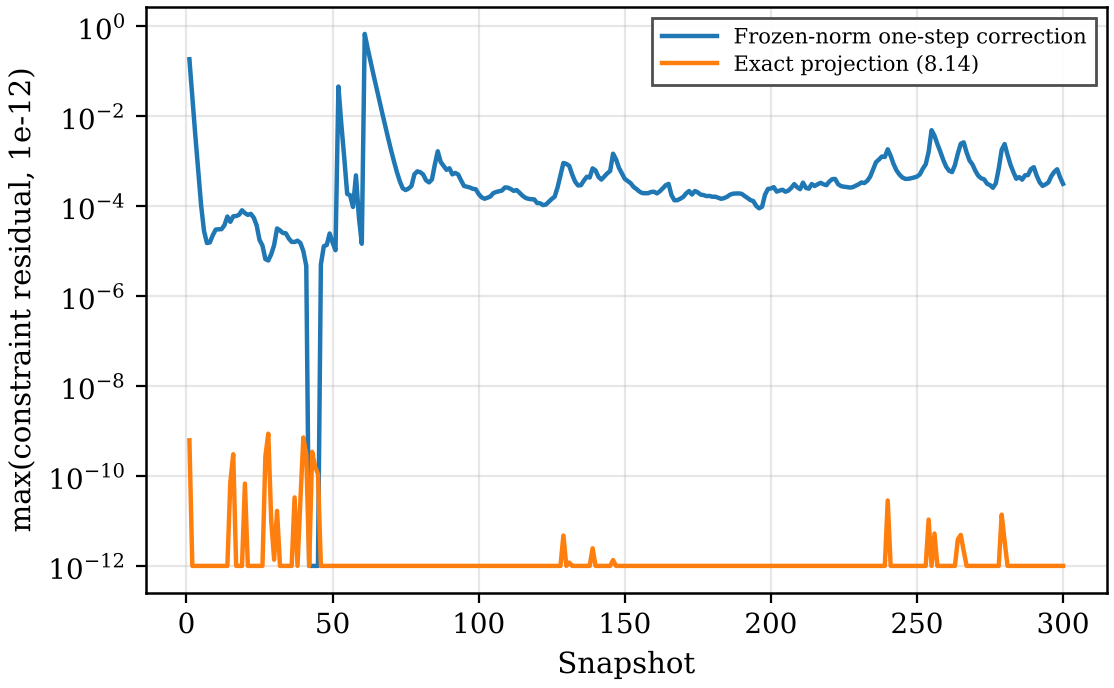

In [17]:
import matplotlib.pyplot as plt
fz = json.load(open(os.path.join(DATA, 'feasibility.json')))['result']['frozen_norm']
fig, ax = plt.subplots(figsize=(6.2, 3.8))
k = np.arange(1, len(fz['residual_trace']) + 1)
ax.semilogy(k, np.maximum(fz['residual_trace'], 1e-12), label='Frozen-norm one-step correction')
ax.semilogy(k, np.maximum(fz['exact_residual_trace'], 1e-12), label='Exact projection (8.14)')
ax.set(xlabel='Snapshot', ylabel='max(constraint residual, 1e-12)')
ax.legend(**LEG); plt.show()

## Comparison with the chapter

Every regenerated number against the value quoted in Chapter 8 (timings are printed for information).

In [18]:
from ch8wrab import verify
verify.main([FIGDIR]);

Section 8.4: subcarrier frequencies
  [OK ] five subcarriers at 292, 296, 300, 304 and 308 GHz
Figures 8.1 and 8.2
  [OK ] Figure 8.1: 16 elements nearly flat (less than 0.5 dB loss)  (-0.25 dB)
  [OK ] Figure 8.1: 64 elements lose several decibels at the band edges  (-4.53 dB)
  [OK ] Figure 8.1: 256 elements reach deep nulls (below -20 dB)  (-51.5 dB)
  [OK ] Figure 8.2: 256 elements lose several dB at a few tenths of a degree; 64 elements stay tolerant  (0.3 deg: 3.17 and 0.38 dB)
Figure 8.3
  [OK ] WRAB band mean (near 15 dB): regenerated 14.943, chapter 15
  [OK ] analog-only band mean: regenerated 1.267, chapter 1.3
  [OK ] WC-single band mean: regenerated 1.828, chapter 1.8
Figure 8.4
  [OK ] wrab at 0 deg: regenerated 16.830, chapter 16.8
  [OK ] analog at 0 deg: regenerated 22.377, chapter 22.4
  [OK ] wc at 0 deg: regenerated 22.887, chapter 22.9
  [OK ] wrab at 2 deg: regenerated 18.887, chapter 18.9
  [OK ] analog at 2 deg: regenerated -0.764, chapter −0.8
  [OK ] wc at 2 d

Table 8.2
  [OK ] 2 deg, adaptive: regenerated 6.237, chapter 6.2
  [OK ] 2 deg, fixed_0.3: regenerated -2.937, chapter −2.9
  [OK ] 2 deg, fixed_1: regenerated -2.939, chapter −2.9
  [OK ] 2 deg, fixed_2: regenerated -2.944, chapter −2.9
  [OK ] 2 deg, fixed_3: regenerated -2.943, chapter −2.9
  [OK ] 2 deg, lcmv: regenerated -5.221, chapter −5.2
  [OK ] 3 deg, adaptive: regenerated 7.710, chapter 7.7
  [OK ] 3 deg, fixed_0.3: regenerated 0.206, chapter 0.2
  [OK ] 3 deg, fixed_1: regenerated -1.728, chapter −1.7
  [OK ] 3 deg, fixed_2: regenerated -2.896, chapter −2.9
  [OK ] 3 deg, fixed_3: regenerated -3.810, chapter −3.8
  [OK ] 3 deg, lcmv: regenerated -5.157, chapter −5.2
  [OK ] 4 deg, adaptive: regenerated 17.789, chapter 17.8
  [OK ] 4 deg, fixed_0.3: regenerated 12.301, chapter 12.3
  [OK ] 4 deg, fixed_1: regenerated 15.262, chapter 15.3
  [OK ] 4 deg, fixed_2: regenerated 18.231, chapter 18.2
  [!! ] 4 deg, fixed_3: regenerated 19.045, chapter 19.1
  [OK ] 4 deg, lcmv: reg

  [OK ] largest constraint residual over all reported runs is 1.0e-9 (at most 1.0e-9)  (1.000e-09)
Timings (machine dependent, for information)
  [info] ms per subcarrier and snapshot, 64/128/256/512 elements: this run 0.20 / 0.26 / 0.80 / 3.49, chapter 0.51 / 0.68 / 1.66 / 6.6
  [info] one WRAB update, Figure 8.11 setting (ms): this run 0.12, chapter 0.16
  [info] one interior-point solve of (8.8) (ms): this run 20.8, chapter 27.6
  [info] ratio: this run 179, chapter about 170
  [info] one WRAB update with 27 constraints at 512 elements (ms): this run 3.09, chapter 3.8

187 of 188 checks passed; mismatches: 4 deg, fixed_3
